# Predicting Student Exam Performance Using Machine Learning

## CT4101 Machine Learning Portfolio Project

### Project Aim

The aim of this project is to investigate whether machine learning can predict students final Mathematics grades using information about their study time, school absences and previous grades.   

Three models are compared:
1. Baseline Model (Dummy Regressor)
2. Linear Regression
3. Decision Tree Regression

The models are evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and 5-fold cross-validation.

## 1. Data Loading and Exploration

This project uses the Student Performance dataset from the UCI Machine Learning Repository.  
The dataset contains information about 395 students studying Mathematics at Portuguese secondary schools.  
It contains 33 variables, including student characteristics, study time, absences and academic grades.  

The target variable is G3, which represents the final Maths grade on a scale from 0 to 20.  
The purpose of this section is to load the dataset, examine its structure, check data quality and explore relationships between variables.  

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("student-mat[1].csv", sep=";")

In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
df.shape

(395, 33)

In [5]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [6]:
# Check for missing data

df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [7]:
# Check for duplicate rows

df.duplicated().sum()

np.int64(0)

In [8]:
df["G3"].describe()

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

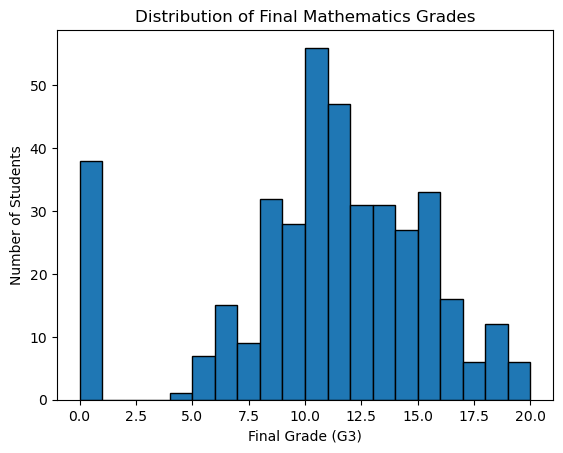

In [9]:
plt.hist(df["G3"], bins=20, edgecolor="black")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.title("Distribution of Final Mathematics Grades")
plt.show()

In [10]:
df.groupby("studytime")["G3"].mean()

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

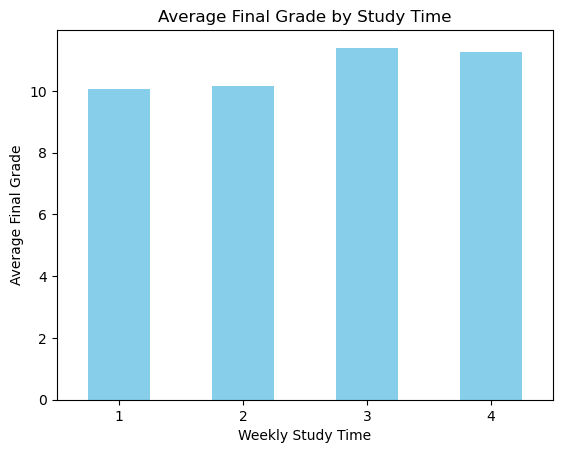

In [11]:
average_grades = df.groupby("studytime")["G3"].mean()
average_grades.plot(kind="bar", color="skyblue")
plt.xlabel("Weekly Study Time")
plt.ylabel("Average Final Grade")
plt.title("Average Final Grade by Study Time")
plt.xticks(rotation=0)
plt.show()

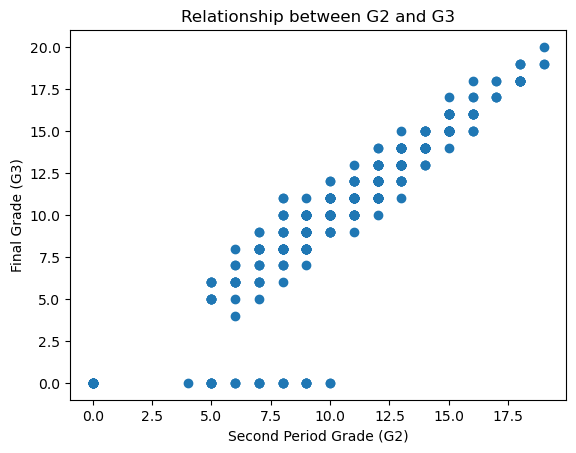

In [12]:
plt.scatter(df["G2"], df["G3"])
plt.xlabel("Second Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.title("Relationship between G2 and G3")
plt.show()

In [13]:
# Correlation

df["G2"].corr(df["G3"])

np.float64(0.9048679892693008)

## 2. Data Preparation

Before training the machine learning models, the dataset was checked for missing values and duplicate rows.  
No missing values or duplicate rows were found.  

Four features were selected to predict students final maths grades:   
- studytime: weekly study time category
- absences: number of school absences
- G1: first-period maths grade
- G2: second-period maths grade

The target variable is G3, representing the final maths grade.  

The dataset was split into:
- 80% training data (316 students)
- 20% testing data (79 students)

The training data is used to train the models, while the testing data is used to evaluate their performance on unseen students.  

A random_state of 42 was used to make the split reproducible.  

In [14]:
x = df[["studytime", "absences", "G1", "G2"]]  # features
y = df["G3"]  # target

x.head()

,studytime,absences,G1,G2
0,2,6,5,6
1,2,4,5,5
2,2,10,7,8
3,3,2,15,14
4,2,4,6,10


In [15]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print("Training students:", x_train.shape[0])
print("Testing students:", x_test.shape[0])

Training students: 316
Testing students: 79


## 3. Model Training 

Three REgression models were used to predict students final maths grade.  

### 3.1 Baseline Model (Dummy Regressor)

The baseline model predicts the average final grade of the students in the training data.  
It does not learn relationships between the input features and the final grade.  
This provides a simple reference point to determine whether our mschine learning models improve prediction accuracy  

### 3.2 Linear Regression

Linear Regression predicts the final grade using a linear relationship between the input features and the target variable.  
It learns coefficients for study time, absences, first-period grades and second-period grades.  
This model was selected because it is simple, interpretable and suitable for predicting numberical value.  

### 3.3 Decision Tree Regression

Decision Tree Regression predicts final grades by splitting the data into groups based on the input features.  
A maximum tree depth of 3 was used to limit the complexity of the model.  
This model was selected to investigate whether a non-linear approach could improve prediction accuracy compared with Linear Regression.  

In [16]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(x_train, y_train)

baseline_predictions = baseline.predict(x_test)
print(baseline_predictions[:5])

[10.32594937 10.32594937 10.32594937 10.32594937 10.32594937]


## 4. Model Evaluation

The performance of the three regression models was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and 5-fold cross-validation.  

### 4.1 Mean Absolute Error (MAE)

MAE measures the average absolute difference between the actual final grades and the predicted grades.  
A lower MAE indicates better predictions.  

### 4.2 Root Mean Squared Error (RMSE)

RMSE measures prediction error while giving greater weight to larger mistakes.  
A lower RMSE indicates better model performance.  

### 4.3 Cross-Validation  

5-fold cross-validation was performed using the training dataset.  
The training data was divided into 5 groups. Each model was trained on 4 groups and validated on the remaining group. This process was repeated 5 times.  
The average validation MAE was calculated to assess how consistently each model performed.  

### 4.4 Model Comparison

The results showed that both Linear Regression and Decision Tree Regression performed considerably better than the baseline model.  
Linear regression achieved the lowest test RMSE and the lowest average cross-validation MAE.  
Decision Tree Regression acheived a slightly lower test MAE, although the difference was very small.  

Overall, Linear Regression was selected as the preferred model because of its competitive predictive performance and simplicity.

In [17]:
from sklearn.metrics import mean_absolute_error

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
print("Baseline MAE:", baseline_mae)

Baseline MAE: 3.64585002403461


In [18]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(x_train, y_train)

linear_predictions = linear_model.predict(x_test)
print(linear_predictions[:5])

linear_mae = mean_absolute_error(y_test, linear_predictions)
print("Linear Regression MAE:", linear_mae)

[ 7.10303103 12.10922942  3.47955361  8.28177318  8.56270885]
Linear Regression MAE: 1.3125749396243542


In [19]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

tree_model.fit(x_train, y_train)

tree_predictions = tree_model.predict(x_test)
print(tree_predictions[:5])

tree_mae = mean_absolute_error(y_test, tree_predictions)
print("Decision Tree MAE:", tree_mae)

[ 9.41772152 11.48484848  6.60869565  9.41772152  9.41772152]
Decision Tree MAE: 1.3099908309101178


In [20]:
results = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression", "Decision Tree"],
    "MAE": [baseline_mae, linear_mae, tree_mae]
})

print(results)

               Model       MAE
0           Baseline  3.645850
1  Linear Regression  1.312575
2      Decision Tree  1.309991


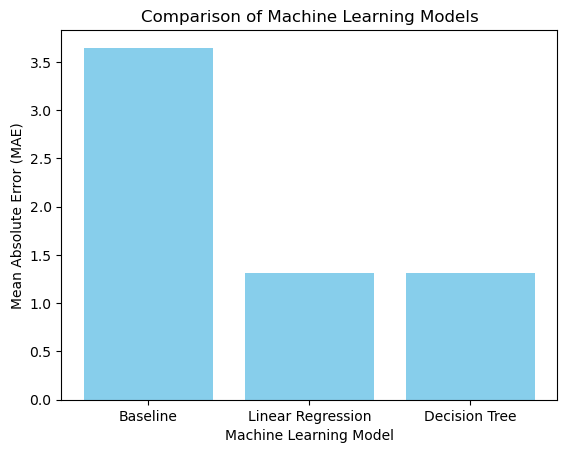

In [21]:
plt.bar(results["Model"], results["MAE"], color="skyblue")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Absolute Error (MAE)")
plt.title("Comparison of Machine Learning Models")
plt.show()

In [22]:
comparison = pd.DataFrame({
    "Actual Grade": y_test,
    "Predicted Grade": linear_predictions
})

comparison["Absolute Error"] = abs(
    comparison["Actual Grade"] - comparison["Predicted Grade"]
)

comparison.head(10)

,Actual Grade,Predicted Grade,Absolute Error
78,10,7.103031,2.896969
371,12,12.109229,0.109229
248,5,3.479554,1.520446
55,10,8.281773,1.718227
390,9,8.562709,0.437291
223,13,12.610665,0.389335
42,18,18.814522,0.814522
234,6,6.844699,0.844699
316,0,6.980266,6.980266
116,14,12.522121,1.477879


In [23]:
comparison.sort_values("Absolute Error", ascending=False).head(10)

,Actual Grade,Predicted Grade,Absolute Error
334,0,8.213331,8.213331
140,0,7.716830,7.716830
316,0,6.980266,6.980266
168,0,5.655586,5.655586
33,12,8.967625,3.032375
370,9,5.975000,3.025000
375,10,7.011415,2.988585
78,10,7.103031,2.896969
157,10,7.422445,2.577555
73,14,11.739750,2.260250


In [24]:
df.loc[334, ["studytime", "absences", "G1", "G2", "G3"]]

studytime     4
absences      0
G1           10
G2            9
G3            0
Name: 334, dtype: object

In [25]:
zero_grades = (df["G3"] == 0).sum()
print("Number of students with a final grade of 0:", zero_grades)

Number of students with a final grade of 0: 38


In [26]:
zero_errors = comparison[comparison["Actual Grade"] == 0]["Absolute Error"].mean()
nonzero_errors = comparison[comparison["Actual Grade"] > 0]["Absolute Error"].mean()

print("MAE for zero grades:", zero_errors)
print("MAE for non-zero grades:", nonzero_errors)

MAE for zero grades: 6.030275158787169
MAE for non-zero grades: 0.9938114113025428


In [27]:
from sklearn.metrics import mean_squared_error
import numpy as np

linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predictions))

print("Linear Regression RMSE:", linear_rmse)
print("Baseline RMSE:", baseline_rmse)
print("Decision Tree RMSE:", tree_rmse)

Linear Regression RMSE: 2.0442542421105143
Baseline RMSE: 4.550180652162387
Decision Tree RMSE: 2.168715787955683


In [28]:
results["RMSE"] = [baseline_rmse, linear_rmse, tree_rmse]
results

,Model,MAE,RMSE
0,Baseline,3.645850,4.550181
1,Linear Regression,1.312575,2.044254
2,Decision Tree,1.309991,2.168716


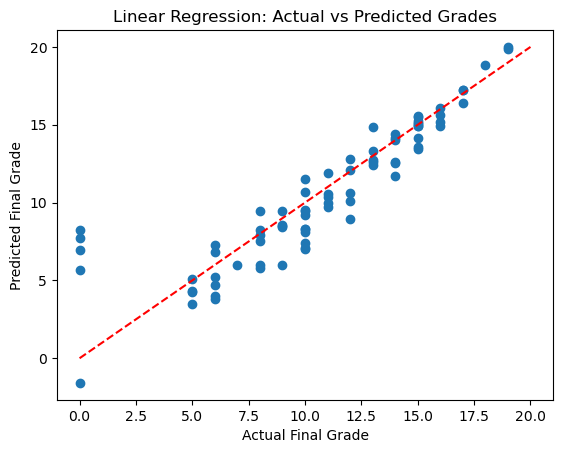

In [29]:
plt.scatter(y_test, linear_predictions)
plt.plot([0,20], [0,20], color="red", linestyle="--")
plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Linear Regression: Actual vs Predicted Grades")
plt.show()

In [30]:
invalid_predictions = ((linear_predictions < 0) | (linear_predictions > 20)).sum()
print("Predictions outside 0-20:", invalid_predictions)

Predictions outside 0-20: 1


In [31]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    LinearRegression(),
    x_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

print("Cross-validation MAE:", -cv_scores)
print("Average MAE:", -cv_scores.mean())

Cross-validation MAE: [1.29595604 1.0272504  1.09956554 1.24872694 1.13002226]
Average MAE: 1.1603042353328186


In [32]:
tree_cv_scores = cross_val_score(
    DecisionTreeRegressor(max_depth=3, random_state=42),
    x_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

print("Decision Tree CV MAE:", -tree_cv_scores)
print("Average Decision Tree MAE:", -tree_cv_scores.mean())

Decision Tree CV MAE: [1.36191261 1.26452003 1.05725725 1.13919518 1.04442248]
Average Decision Tree MAE: 1.1734615114436635


In [33]:
baseline_cv_scores = cross_val_score(
    DummyRegressor(strategy="mean"),
    x_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

print("Baseline CV MAE:", -baseline_cv_scores)
print("Average Baseline MAE:", -baseline_cv_scores.mean())

Baseline CV MAE: [3.76450893 3.13049752 3.25396825 3.76303407 3.0296129 ]
Average Baseline MAE: 3.388324334180312


In [34]:
results["CV MAE"] = [
    -baseline_cv_scores.mean(),
    -cv_scores.mean(),
    -tree_cv_scores.mean()
]
results.round(4)

,Model,MAE,RMSE,CV MAE
0,Baseline,3.6459,4.5502,3.3883
1,Linear Regression,1.3126,2.0443,1.1603
2,Decision Tree,1.3100,2.1687,1.1735


## 5. Conclusions and Limitations

### 5.1 Conclusions

The aim of this projecy was to predict students final Maths grades using machine learning.  
Three regression models were evaluated: a Baseline model, linear gression and decision tree regression.  
Both Linear Regression and Decision Tree regression preformed considerably better than the baseline.  

Linear Regression acheived a test MAE of 1.3126 and a test  RMSE of 2.0443. Its average 5-fold cross-validation MAE was 1.1603.
Decision Tree Regression achieved a slightly lower test MAE of 1.3100, but Linear Regression had a lower RMSE and cross-validation MAE.

Overall, Linear Regression was selected as the preferred model because of its simplicity and competitive performance.

### 5.2 Limitations

**Zero Final Grades**

The dataset contains 38 students who received a final grade of zero.

The Linear Regression model struggled to predict these students accurately. Its average absolute error for students with a final grade of zero in the test set was approximately 6.03, compared with 0.99 for students with non-zero grades.
This suggests that the model has difficulty predicting unusually low final grades.

**Dependence on Previous Grades**

The model relies heavily on previous academic performance, particularly second-period grades(G2).
This means the model is most suitable for making predictions after earlier grades are available, rather than at the beginning of the school year.

**Dataset Size**

The dataset contains only 395 students from Portuguese secondary schools.
The results may not generalise to students in other countries, schools or educational systems.

**Predictions Outside the Grade Range**

Linear Regression can produce predictions outside the valid grade range of 0 to 20.
One prediction in the test set fell outside this range.

**Model Selection**

The models were compared using cross-validation and a held-out test set. Because the test results were also considered when selecting the preferred model, the reported test performance should be interpreted as exploratory.

### 5.3 Responsible Use

Machine learning predictions should not be used as the sole basis for decisions about students' academic abilities or opportunities.
Academic performance can be influenced by many factors that are not included in this model.
Predictions should therefore be interpreted cautiously and should not replace teachers' professional judgement. 


### 5.4 Next Steps

The next stage of this project will focus on improving the documentation and interpretation of the results.  
The final report will provide a more detailed discussion of the models, evaluation metrics and limitations.  
The project will also include a complete assistance declaration, reproducibility instructions and a five-minute demonstartion video. 

No further model tuning will be carried out using the held-out test set.  

## 6. AI Assistance Declaration

ChatGPT (OpenAI) was used to assist with the development of this machine learning project, particularly because I had limited previous experience with machine learning.

AI assistance included:  
- explaining machine learning concepts.
- help me understand python syntax.
- help build a plan of action.